# Clase 10 · Máquinas de soporte vectorial: clasificación y regresión

**INF-396 Introducción a la Ciencia de Datos** · Universidad Técnica Federico Santa María · viernes 13 de noviembre de 2026

**Qué hacemos hoy.** Las máquinas de soporte vectorial (SVM) separan dos clases con la recta, o el hiperplano, de mayor margen. Primero clasificamos la especie de los pingüinos y vemos cómo evaluar el clasificador con datos de prueba y validación cruzada. Después usamos la misma idea para predecir un número, con SVR, y la comparamos con los modelos de la clase 07 en el salario de los beisbolistas. Las lecturas son las secciones 9.1 a 9.4 de James, Witten, Hastie y Tibshirani (2013) y el tutorial de SVR de Smola y Schölkopf (2004).

## 1. Preparación

De **scikit-learn** se usan `SVC` (el clasificador de soporte vectorial) y `SVR` (la regresión de soporte vectorial), además de lo de las clases 07 y 08 para separar, estandarizar y elegir parámetros.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: estandarizar, separar, elegir parámetros y los modelos de hoy
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC, SVR
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.datasets import make_circles

sns.set_theme(style="whitegrid")
%config InlineBackend.figure_format = "retina"
pd.options.display.float_format = "{:.3f}".format

In [2]:
# Datos locales del repositorio clonado
BASE = "datos/"
# Alternativa por URL, si no tiene el repositorio clonado:
# BASE = "https://raw.githubusercontent.com/daniopitz/cienciadatos/main/datos/"

## 2. Los pingüinos

Los mismos datos de la clase 08. Se quitan los pingüinos sin alguna de las cuatro medidas.

In [3]:
pinguinos = pd.read_csv(BASE + "clase08/pinguinos_palmer.csv")

In [4]:
#columnas que me interesan para el análisis
medidas = ["largo_pico_mm", "alto_pico_mm", "largo_aleta_mm", "masa_g"]

In [5]:
#elimina filas con valores faltantes en las columnas de medidas y reinicia el índice
pinguinos = pinguinos.dropna(subset=medidas).reset_index(drop=True)


In [6]:
print("pingüinos:", len(pinguinos))
pinguinos["especie"].value_counts()

pingüinos: 342


especie
Adelia     151
Papúa      123
Barbijo     68
Name: count, dtype: int64

**Un primer vistazo.** El largo y el alto del pico de las tres especies. Adelia y papúa se pueden separar con una recta. Adelia y barbijo se traslapan un poco.

In [7]:
pinguinos.head()

,especie,isla,largo_pico_mm,alto_pico_mm,largo_aleta_mm,masa_g,sexo,anio
0,Adelia,Torgersen,39.100,18.700,181.000,3750.000,macho,2007
1,Adelia,Torgersen,39.500,17.400,186.000,3800.000,hembra,2007
2,Adelia,Torgersen,40.300,18.000,195.000,3250.000,hembra,2007
3,Adelia,Torgersen,36.700,19.300,193.000,3450.000,hembra,2007
4,Adelia,Torgersen,39.300,20.600,190.000,3650.000,macho,2007


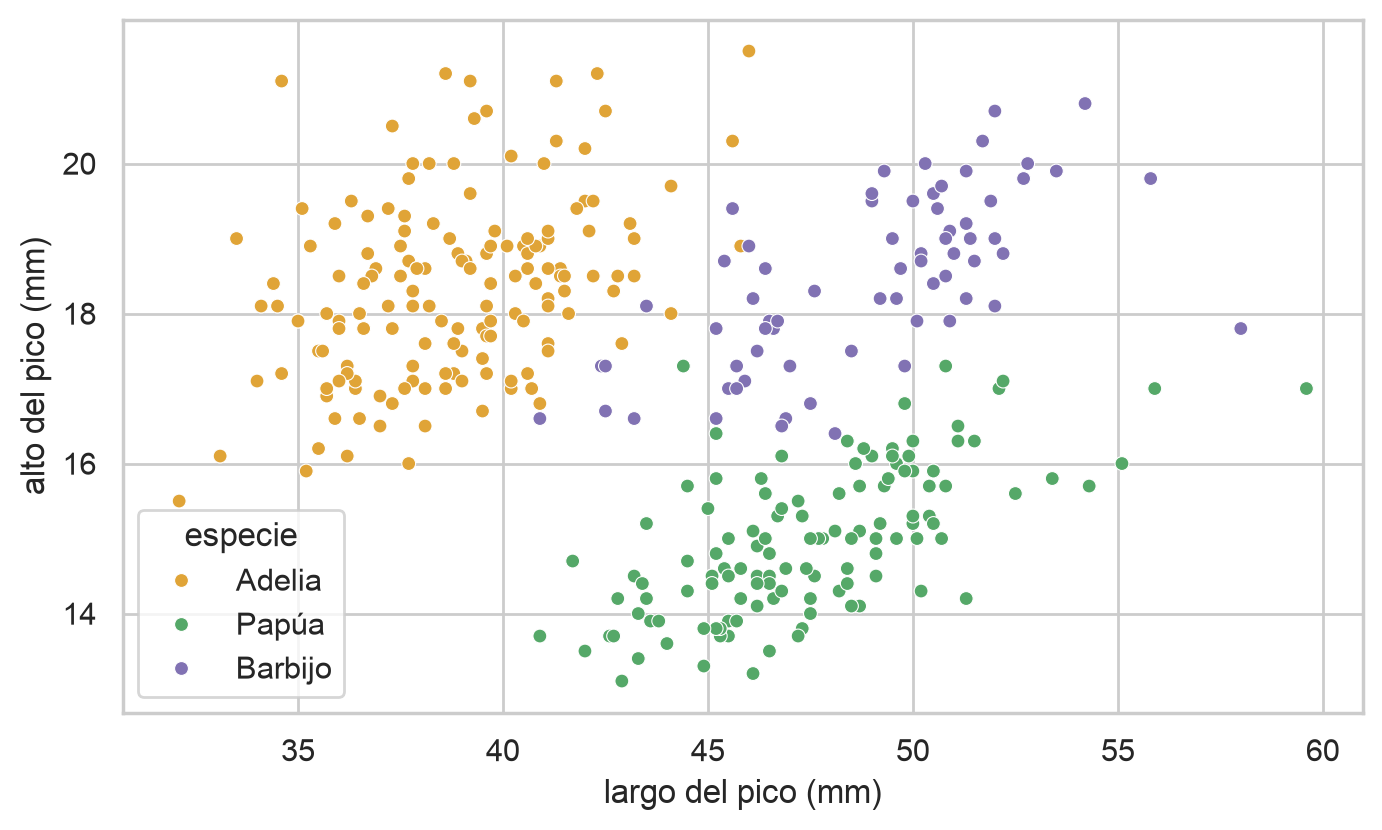

In [8]:
colores = {"Adelia": "#E0A437", "Barbijo": "#8172B3", "Papúa": "#55A868"}

plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=pinguinos, x="largo_pico_mm", y="alto_pico_mm", hue="especie", palette=colores, s=25)
plt.xlabel("largo del pico (mm)")
plt.ylabel("alto del pico (mm)")
plt.show()

## 3. SVM para clasificación

**Objetivo:** clasificar la especie con el hiperplano de mayor margen.

Primero dos especies que una recta separa, Adelia y papúa, con el largo y el alto del pico. Como SVM depende de las distancias, se estandarizan las medidas.

In [9]:
dos = pinguinos[pinguinos["especie"].isin(["Adelia", "Papúa"])]
dos.head()

,especie,isla,largo_pico_mm,alto_pico_mm,largo_aleta_mm,masa_g,sexo,anio
0,Adelia,Torgersen,39.100,18.700,181.000,3750.000,macho,2007
1,Adelia,Torgersen,39.500,17.400,186.000,3800.000,hembra,2007
2,Adelia,Torgersen,40.300,18.000,195.000,3250.000,hembra,2007
3,Adelia,Torgersen,36.700,19.300,193.000,3450.000,hembra,2007
4,Adelia,Torgersen,39.300,20.600,190.000,3650.000,macho,2007


In [10]:
pico = ["largo_pico_mm", "alto_pico_mm"]
escala = StandardScaler().fit(dos[pico])
X_dos = escala.transform(dos[pico])
y_dos = dos["especie"]

In [11]:
X_dos 

array([[-6.94729335e-01,  9.27421442e-01],
       [-6.17599741e-01,  2.80569048e-01],
       [-4.63340553e-01,  5.79116307e-01],
       [-1.15750690e+00,  1.22596870e+00],
       [-6.56164538e-01,  1.87282109e+00],
       [-7.33294131e-01,  4.79600554e-01],
       [-6.75446936e-01,  1.37524233e+00],
       [-1.65884926e+00,  6.28874183e-01],
       [-1.35539779e-01,  1.67378959e+00],
       [-9.45400515e-01,  1.31295419e-01],
       [-9.45400515e-01,  2.30811171e-01],
       [-3.09081365e-01,  3.80084801e-01],
       [-7.91141327e-01,  2.17136835e+00],
       [-1.56243727e+00,  2.12161048e+00],
       [-1.17678930e+00,  4.79600554e-01],
       [-7.71858928e-01,  1.07669507e+00],
       [-3.91277867e-02,  1.92257897e+00],
       [-1.60100206e+00,  7.78147812e-01],
       [ 6.35756160e-01,  2.32064198e+00],
       [-9.45400515e-01,  7.28389936e-01],
       [-9.64682913e-01,  9.27421442e-01],
       [-1.31176609e+00,  1.17621082e+00],
       [-8.68270921e-01,  6.28874183e-01],
       [-7.

In [12]:
y_dos

0      Adelia
1      Adelia
2      Adelia
3      Adelia
4      Adelia
        ...  
269     Papúa
270     Papúa
271     Papúa
272     Papúa
273     Papúa
Name: especie, Length: 274, dtype: str

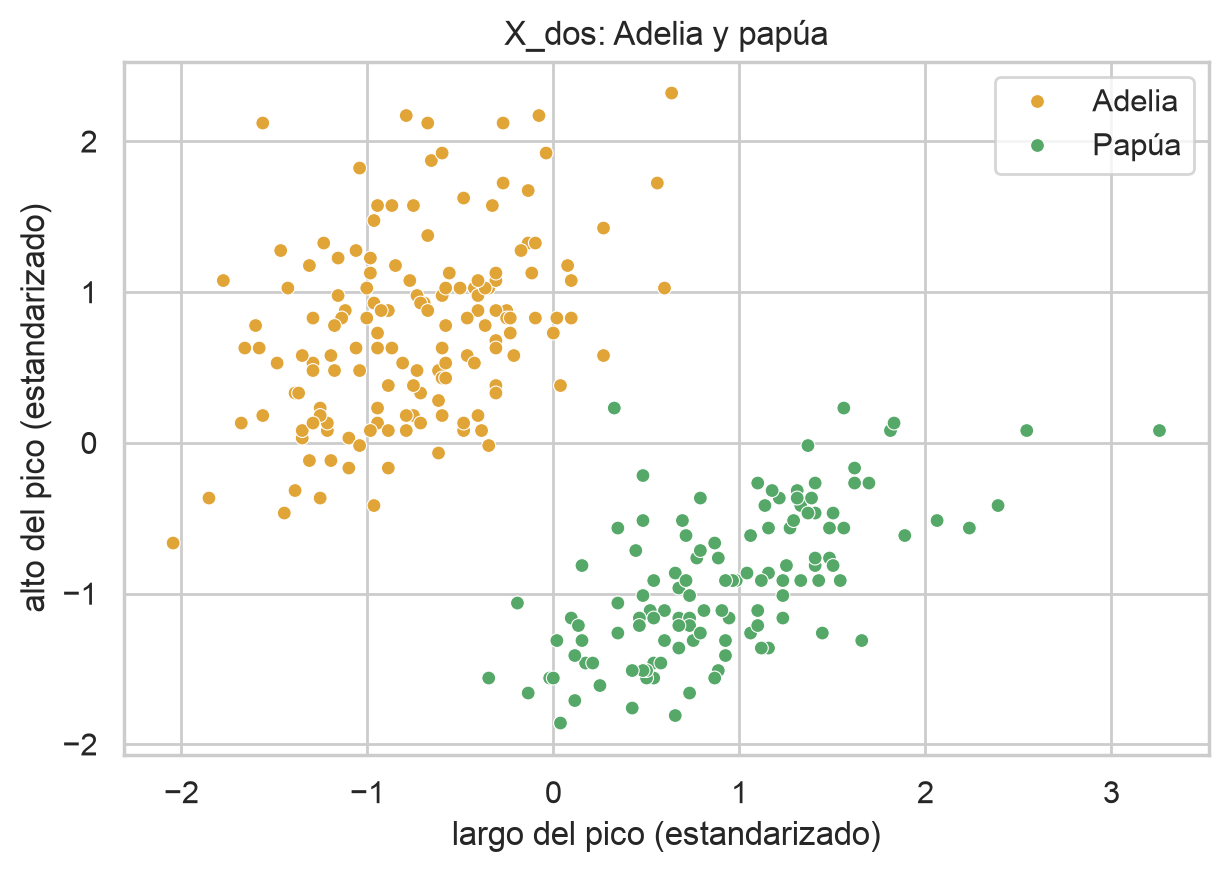

In [13]:
plt.figure(figsize=(7, 4.5))
sns.scatterplot(x=X_dos[:, 0], y=X_dos[:, 1], hue=y_dos.values,
                palette={"Adelia": "#E0A437", "Papúa": "#55A868"}, s=25)
plt.xlabel("largo del pico (estandarizado)")
plt.ylabel("alto del pico (estandarizado)")
plt.title("X_dos: Adelia y papúa")
plt.show()

**Margen máximo.** El SVM elige la recta que deja la calle más ancha entre las dos especies. Los pingüinos que tocan los bordes de esa calle son los vectores de soporte, y solo ellos deciden dónde va la recta. scikit-learn siempre usa margen blando, pero con un C enorme casi no permite violaciones y el resultado es el clasificador de margen máximo. Quedan 3 vectores de soporte y ningún error.

In [14]:
svm_duro = SVC(kernel="linear", C=1e6).fit(X_dos, y_dos)
print("vectores de soporte por clase:", svm_duro.n_support_)
print("errores:", (svm_duro.predict(X_dos) != y_dos).sum())

vectores de soporte por clase: [2 1]
errores: 0


In [15]:
print(svm_duro.classes_)      
print(svm_duro.n_support_) 

['Adelia' 'Papúa']
[2 1]


Los vectores de soporte son tres pingüinos, dos Adelia y un papúa. `support_` da su posición en la tabla.

In [16]:
dos.iloc[svm_duro.support_][["especie"] + pico]

,especie,largo_pico_mm,alto_pico_mm
75,Adelia,40.900,16.800
128,Adelia,44.100,18.000
188,Papúa,44.400,17.300


**El gráfico del margen.** La función `dibujar_svm` pinta los pingüinos, la recta, los bordes del margen y encierra en un círculo los vectores de soporte. Para dibujar la recta calcula f(x) en una grilla de puntos que cubre todo el gráfico: la recta son los puntos con f(x) = 0, y los bordes del margen, los puntos con f(x) = −1 y f(x) = 1 (la escala de scikit-learn).

In [17]:
def dibujar_svm(modelo, escala, datos, columnas, eje, titulo=""):
    # los pingüinos
    sns.scatterplot(data=datos, x=columnas[0], y=columnas[1], hue="especie", palette=colores, s=25, ax=eje)

    # una grilla de puntos que cubre el gráfico, para calcular f(x) en cada uno
    x1 = np.linspace(datos[columnas[0]].min() - 1, datos[columnas[0]].max() + 1, 200)
    x2 = np.linspace(datos[columnas[1]].min() - 1, datos[columnas[1]].max() + 1, 200)
    g1, g2 = np.meshgrid(x1, x2)
    grilla = pd.DataFrame({columnas[0]: g1.ravel(), columnas[1]: g2.ravel()})
    f = modelo.decision_function(escala.transform(grilla)).reshape(g1.shape)

    # la recta (f = 0) y los bordes del margen (f = -1 y f = 1)
    eje.contour(g1, g2, f, levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"], linewidths=[1, 2, 1])

    # los vectores de soporte, encerrados en un círculo
    soporte = datos.iloc[modelo.support_]
    eje.scatter(soporte[columnas[0]], soporte[columnas[1]], s=150, facecolors="none", edgecolors="black", linewidths=1.5)

    eje.set_xlabel("largo del pico (mm)")
    eje.set_ylabel("alto del pico (mm)")
    eje.set_title(titulo)

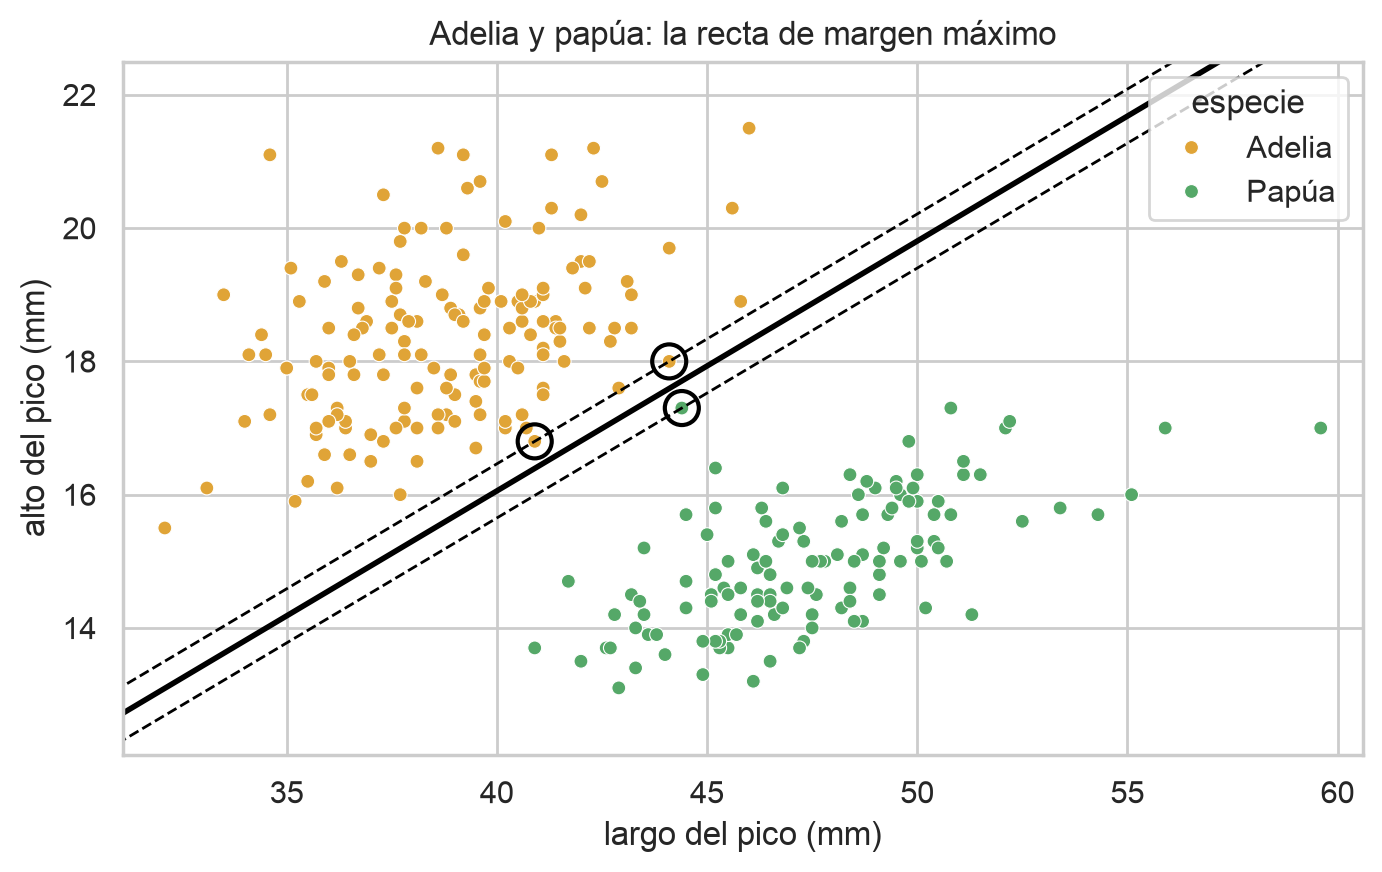

In [18]:
fig, eje = plt.subplots(figsize=(8, 4.5))
dibujar_svm(svm_duro, escala, dos, pico, eje, "Adelia y papúa: la recta de margen máximo")
plt.show()

**Los coeficientes que eligió el algoritmo.** `intercept_` es β₀ y `coef_` son β₁ y β₂, en las medidas estandarizadas. Con ellos, f(x) = β₀ + β₁x₁ + β₂x₂ le da un puntaje a cada pingüino: positivo de un lado de la recta y negativo del otro. `decision_function` hace esa cuenta.

In [19]:
b0 = svm_duro.intercept_[0]
b1, b2 = svm_duro.coef_[0]
print(f"β0 = {b0:.3f}, β1 = {b1:.3f}, β2 = {b2:.3f}")



β0 = 0.576, β1 = 4.788, β2 = -4.948


In [20]:
#vectores de soporte
svm_duro.support_

array([ 75, 128, 188], dtype=int32)

In [21]:
x_sv=X_dos[svm_duro.support_]
x_sv

array([[-0.34764616, -0.01797821],
       [ 0.26939059,  0.57911631],
       [ 0.32723778,  0.23081117]])

In [22]:
print("a mano:            ", (b0 + b1 * x_sv[:, 0] + b2 * x_sv[:, 1]).round(3))
print("decision_function: ", svm_duro.decision_function(x_sv).round(3))

a mano:             [-1. -1.  1.]
decision_function:  [-1. -1.  1.]


In [23]:
print(svm_duro.classes_)

['Adelia' 'Papúa']


**Qué significa `[-1. -1.  1.]`.** Son los puntajes f(x) de los tres vectores de soporte, en el mismo orden de la tabla de arriba: Adelia, Adelia y papúa. El signo dice la especie: negativo es Adelia y positivo es papúa. Dan justo −1 y 1 porque los vectores de soporte están sobre los bordes del margen, y scikit-learn escala los β para que esos bordes sean f(x) = −1 y f(x) = 1. Las dos líneas son iguales porque `decision_function` hace la misma cuenta que hicimos a mano con los β.

**La ecuación de la recta, en milímetros.** El gráfico de arriba está en milímetros, pero el SVM se entrenó con las medidas estandarizadas, así que β₀, β₁ y β₂ están en esa escala. Para escribir la ecuación de esa misma recta en milímetros hay que convertirlos.

Estandarizar una medida es restarle su media y dividirla por su desviación estándar. Al reemplazar eso en f(x) y ordenar, queda:

- el peso del largo, en milímetros, es β₁ dividido por la desviación del largo;
- el peso del alto, en milímetros, es β₂ dividido por la desviación del alto;
- la constante es β₀ − β₁·media del largo/desviación del largo − β₂·media del alto/desviación del alto.

In [24]:
media, desv = escala.mean_, escala.scale_
print("media del largo y del alto:", media.round(2))
print("desviación del largo y del alto:", desv.round(2))

b1_mm, b2_mm = b1 / desv[0], b2 / desv[1]
b0_mm = b0 - b1 * media[0] / desv[0] - b2 * media[1] / desv[1]
print(f"f(x) de scikit-learn, en mm: {b0_mm:.2f} + {b1_mm:.2f}·x1 + ({b2_mm:.2f})·x2")

media del largo y del alto: [42.7  16.84]
desviación del largo y del alto: [5.19 2.01]
f(x) de scikit-learn, en mm: 2.61 + 0.92·x1 + (-2.46)·x2


La recta son los puntos con f(x) = 0. Si los tres coeficientes se dividen por un mismo número, la recta no cambia; solo cambia la escala del puntaje. Dividiendo por 2,46 y dejando x₂ a un lado queda la recta en su forma conocida, que es la de las slides.

In [25]:
intercepto = -b0_mm / b2_mm
pendiente = -b1_mm / b2_mm
print(f"recta: x2 = {intercepto:.2f} + {pendiente:.2f}·x1")

recta: x2 = 1.06 + 0.37·x1


**La recta dibujada con su ecuación.** Ahora se dibuja la recta directamente con el intercepto y la pendiente, sobre los pingüinos en milímetros. Es la misma recta negra del gráfico del margen, de más arriba.

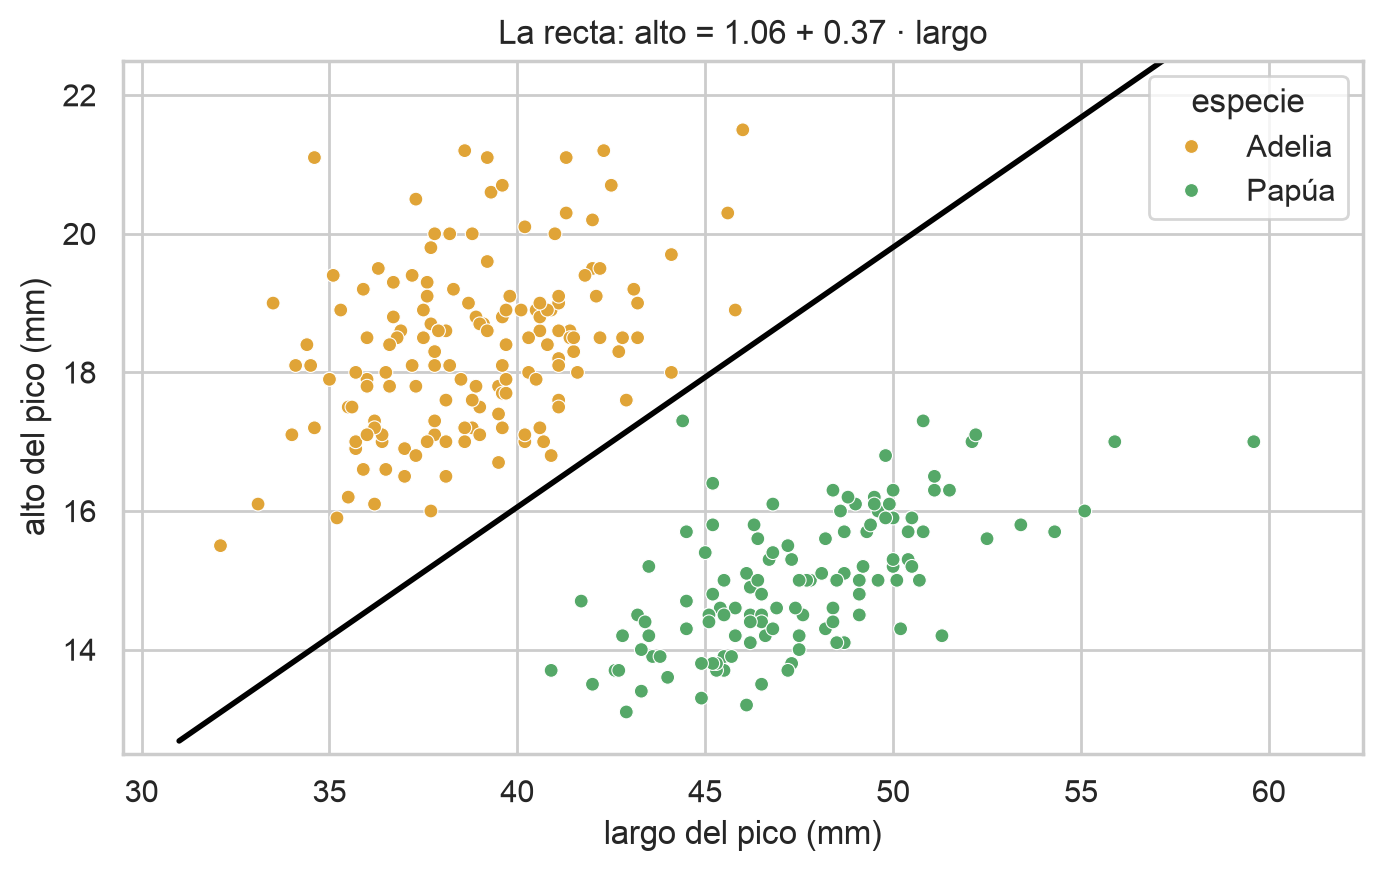

In [26]:
largos = np.array([31, 61])

plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=dos, x="largo_pico_mm", y="alto_pico_mm", hue="especie", palette=colores, s=25)
plt.plot(largos, intercepto + pendiente * largos, color="black", linewidth=2)
plt.ylim(12.5, 22.5)
plt.xlabel("largo del pico (mm)")
plt.ylabel("alto del pico (mm)")
plt.title(f"La recta: alto = {intercepto:.2f} + {pendiente:.2f} · largo")
plt.show()

## 4. El clasificador andando

**Objetivo:** entrenar un SVM con las tres especies y las cuatro medidas, y ver cómo le va con pingüinos que no vio.

Se separa un 30 % de los pingüinos para la prueba, con la misma proporción de cada especie (`stratify`). Las medidas se estandarizan con la media y la desviación del entrenamiento, como en la clase 07.

In [27]:
medidas

['largo_pico_mm', 'alto_pico_mm', 'largo_aleta_mm', 'masa_g']

In [28]:
#dividimos el conjunto de datos en entrenamiento y prueba de manera proporcional por clase

In [29]:
X_tr, X_te, y_tr, y_te = train_test_split(
    pinguinos[medidas], pinguinos["especie"], test_size=0.3,
    random_state=1, stratify=pinguinos["especie"])

#estandardizamos las variables de entrada para que tengan media 0 y desviación estándar 1 
#solo con los datos de entrenamiento, y luego aplicamos la misma transformación a los datos de prueba
escala4 = StandardScaler().fit(X_tr)
Z_tr = escala4.transform(X_tr)
Z_te = escala4.transform(X_te)
print("entrenamiento:", len(X_tr), "| prueba:", len(X_te))

entrenamiento: 239 | prueba: 103


**Entrenar y predecir.** Se entrena un SVM lineal con C = 1, el valor por omisión de scikit-learn, y se le pide la especie de cada pingüino de prueba con `predict`. La tabla muestra los primeros 8 pingüinos de prueba, con la especie real y la que predijo el modelo.

In [30]:
svm3 = SVC(kernel="linear", C=1).fit(Z_tr, y_tr)
prediccion = svm3.predict(Z_te)
prediccion


array(['Papúa', 'Papúa', 'Adelia', 'Papúa', 'Barbijo', 'Adelia', 'Papúa',
       'Adelia', 'Adelia', 'Papúa', 'Adelia', 'Papúa', 'Adelia', 'Papúa',
       'Barbijo', 'Barbijo', 'Papúa', 'Barbijo', 'Adelia', 'Papúa',
       'Papúa', 'Adelia', 'Barbijo', 'Adelia', 'Papúa', 'Adelia', 'Papúa',
       'Adelia', 'Adelia', 'Adelia', 'Adelia', 'Papúa', 'Papúa',
       'Barbijo', 'Adelia', 'Papúa', 'Adelia', 'Adelia', 'Adelia',
       'Barbijo', 'Adelia', 'Adelia', 'Papúa', 'Barbijo', 'Adelia',
       'Adelia', 'Papúa', 'Barbijo', 'Adelia', 'Papúa', 'Papúa', 'Papúa',
       'Adelia', 'Barbijo', 'Adelia', 'Barbijo', 'Adelia', 'Adelia',
       'Papúa', 'Papúa', 'Barbijo', 'Adelia', 'Barbijo', 'Papúa',
       'Adelia', 'Papúa', 'Barbijo', 'Papúa', 'Barbijo', 'Papúa', 'Papúa',
       'Adelia', 'Papúa', 'Papúa', 'Papúa', 'Adelia', 'Adelia', 'Papúa',
       'Barbijo', 'Adelia', 'Adelia', 'Adelia', 'Adelia', 'Adelia',
       'Papúa', 'Papúa', 'Adelia', 'Adelia', 'Adelia', 'Adelia', 'Adelia',
       'P

In [31]:
comparacion = X_te.copy()
comparacion["especie_real"] = y_te
comparacion["especie_predicha"] = prediccion
comparacion.head(8)

,largo_pico_mm,alto_pico_mm,largo_aleta_mm,masa_g,especie_real,especie_predicha
170,48.700,15.100,222.000,5350.000,Papúa,Papúa
251,48.500,15.000,219.000,4850.000,Papúa,Papúa
328,42.500,17.300,187.000,3350.000,Barbijo,Adelia
183,45.100,14.500,207.000,5050.000,Papúa,Papúa
331,49.300,19.900,203.000,4050.000,Barbijo,Barbijo
49,39.600,17.700,186.000,3500.000,Adelia,Adelia
242,52.200,17.100,228.000,5400.000,Papúa,Papúa
57,36.500,16.600,181.000,2850.000,Adelia,Adelia


**¿Cuántos acierta?** Se cuentan los pingüinos de prueba en que la especie predicha es la real. La matriz de confusión muestra además en qué se equivoca: cada fila es la especie real y cada columna la predicha, y los aciertos están en la diagonal.

aciertos en prueba: 101 de 103 = 98.1 %


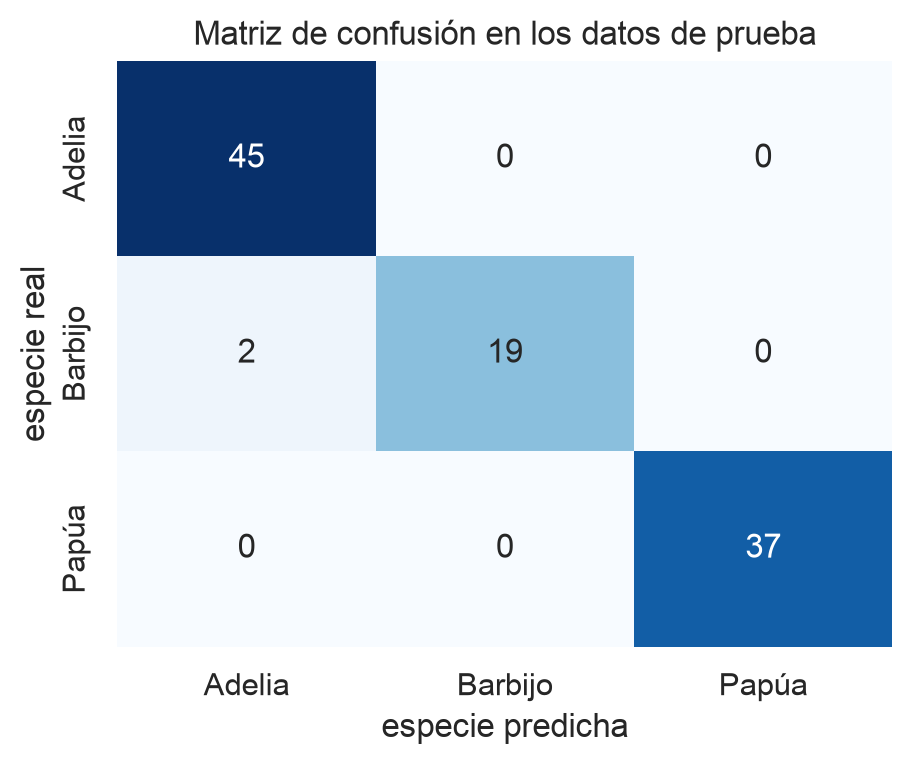

In [32]:
aciertos = (prediccion == y_te).sum()
print("aciertos en prueba:", aciertos, "de", len(y_te), "=", round(100 * aciertos / len(y_te), 1), "%")

matriz = pd.crosstab(y_te, prediccion, rownames=["especie real"], colnames=["especie predicha"])
plt.figure(figsize=(5, 3.8))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matriz de confusión en los datos de prueba")
plt.show()

## 5. Cómo cambia el clasificador con cada parámetro

**Objetivo:** ver qué hace cada parámetro de `SVC`.

Se entrena el mismo clasificador cambiando un parámetro a la vez. En cada tabla, una fila es un valor del parámetro, y las columnas son el porcentaje de aciertos en los datos de entrenamiento y en los de prueba.

**El parámetro C**, con kernel lineal. C es el castigo por cada pingüino que viola el margen. La tabla agrega cuántos vectores de soporte quedan con cada valor.

In [33]:
filas = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    modelo = SVC(kernel="linear", C=C).fit(Z_tr, y_tr)
    filas.append({
        "C": C,
        "vectores_soporte": modelo.n_support_.sum(),
        "aciertos_entrenamiento": round(100 * (modelo.predict(Z_tr) == y_tr).mean(), 1),
        "aciertos_prueba": round(100 * (modelo.predict(Z_te) == y_te).mean(), 1),
    })
efecto_C = pd.DataFrame(filas)
efecto_C

,C,vectores_soporte,aciertos_entrenamiento,aciertos_prueba
0,0.001,222,69.900,69.900
1,0.010,138,94.600,89.300
2,0.100,55,98.300,97.100
3,1.000,21,99.600,98.100
4,10.000,13,99.200,99.000
5,100.000,10,100.000,99.000


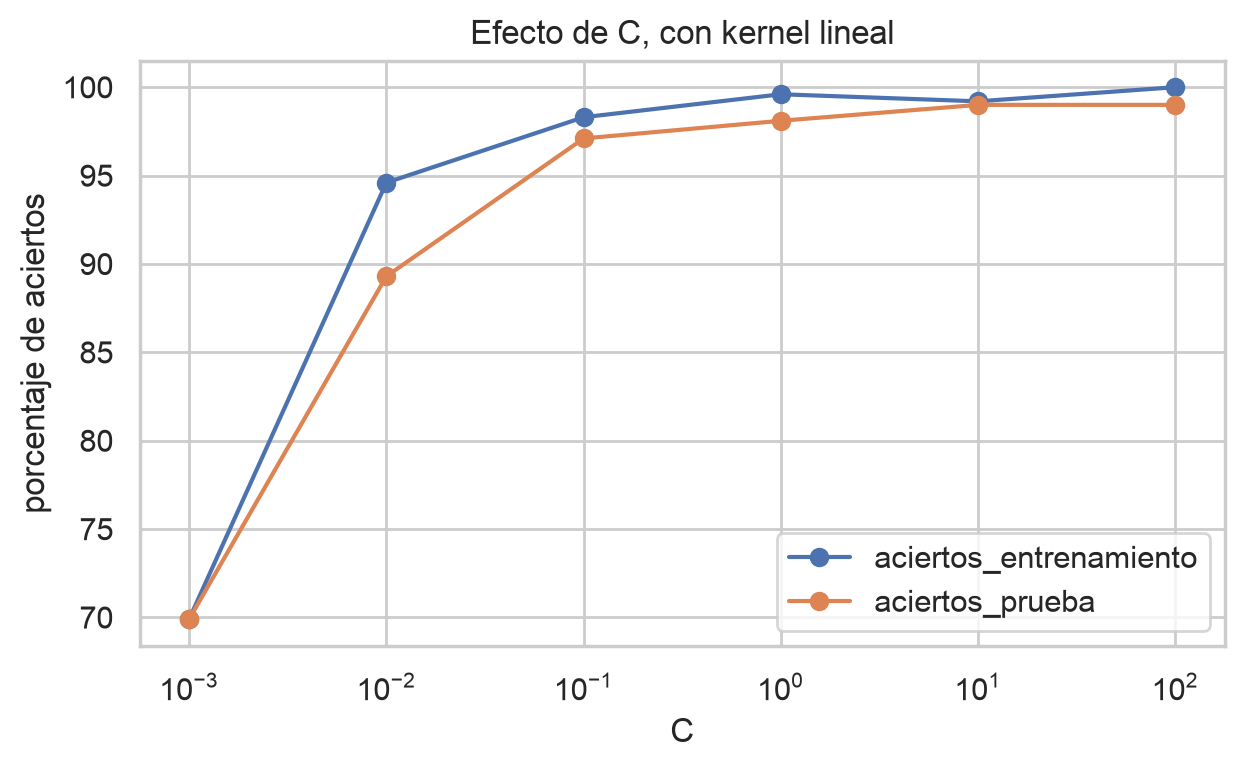

In [34]:
efecto_C.plot(x="C", y=["aciertos_entrenamiento", "aciertos_prueba"], marker="o", logx=True, figsize=(7, 3.8))
plt.ylabel("porcentaje de aciertos")
plt.title("Efecto de C, con kernel lineal")
plt.show()

Con C = 0,001 el margen es tan ancho que casi todos los pingüinos son vectores de soporte, y el modelo acierta cerca del 70 %. Desde C = 1 acierta el 98 % o más en la prueba.

**El kernel**, con C = 1. `linear` da una frontera recta, y `poly` y `rbf` (el radial) dan fronteras curvas.

In [35]:
filas = []
for kernel in ["linear", "poly", "rbf"]:
    modelo = SVC(kernel=kernel, C=1).fit(Z_tr, y_tr)
    filas.append({
        "kernel": kernel,
        "aciertos_entrenamiento": round(100 * (modelo.predict(Z_tr) == y_tr).mean(), 1),
        "aciertos_prueba": round(100 * (modelo.predict(Z_te) == y_te).mean(), 1),
    })
pd.DataFrame(filas)

,kernel,aciertos_entrenamiento,aciertos_prueba
0,linear,99.600,98.100
1,poly,95.400,91.300
2,rbf,99.200,96.100


Con estos datos gana el kernel lineal: las tres especies ya se separan bien con fronteras rectas.

**El parámetro gamma**, con kernel radial y C = 1. gamma dice qué tan rápido baja el parecido entre dos pingüinos con la distancia.

In [36]:
filas = []
for gamma in [0.001, 0.01, 0.1, 1, 10, 100]:
    modelo = SVC(kernel="rbf", C=1, gamma=gamma).fit(Z_tr, y_tr)
    filas.append({
        "gamma": gamma,
        "aciertos_entrenamiento": round(100 * (modelo.predict(Z_tr) == y_tr).mean(), 1),
        "aciertos_prueba": round(100 * (modelo.predict(Z_te) == y_te).mean(), 1),
    })
efecto_gamma = pd.DataFrame(filas)
efecto_gamma

,gamma,aciertos_entrenamiento,aciertos_prueba
0,0.001,80.300,79.600
1,0.010,97.100,97.100
2,0.100,99.200,97.100
3,1.000,99.600,97.100
4,10.000,100.000,79.600
5,100.000,100.000,43.700


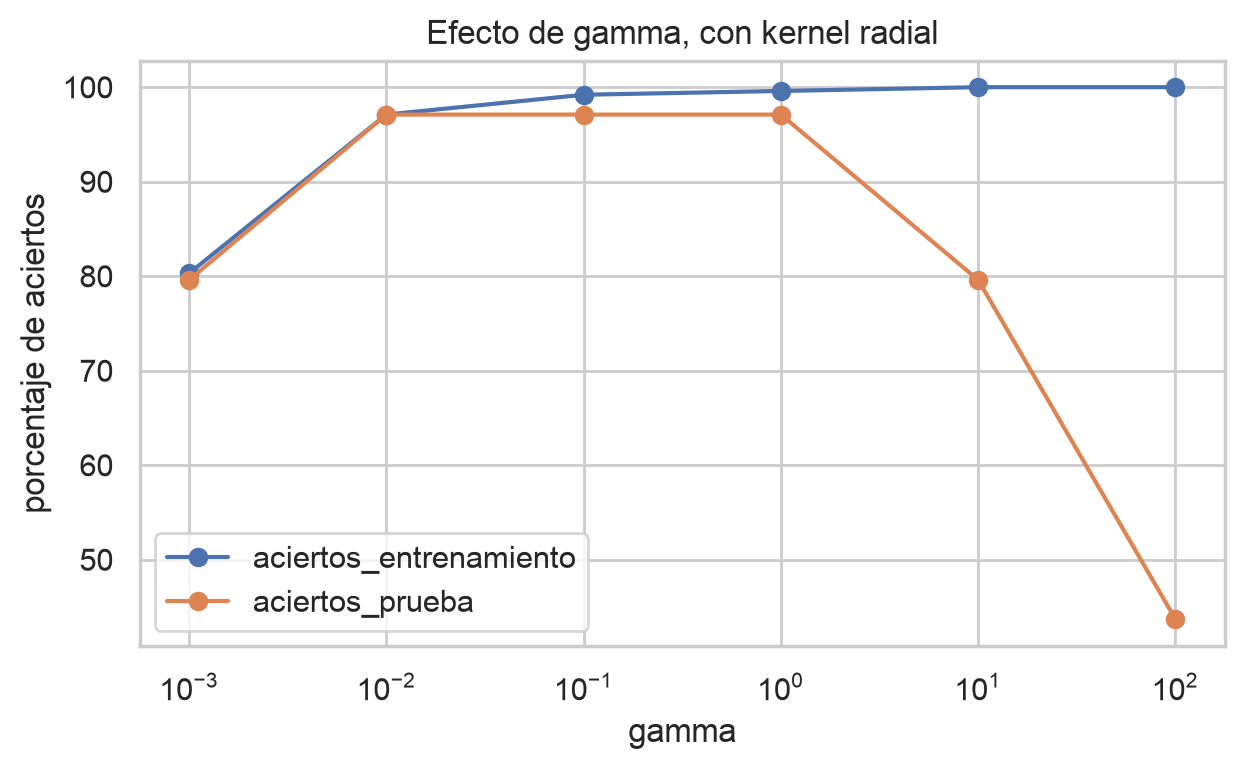

In [37]:
efecto_gamma.plot(x="gamma", y=["aciertos_entrenamiento", "aciertos_prueba"], marker="o", logx=True, figsize=(7, 3.8))
plt.ylabel("porcentaje de aciertos")
plt.title("Efecto de gamma, con kernel radial")
plt.show()

Con gamma = 100 el modelo acierta el 100 % del entrenamiento y menos de la mitad de la prueba. Se aprendió de memoria los pingüinos de entrenamiento y falla con los nuevos. Es sobreajuste, como en la clase 07. Por eso los parámetros no se eligen mirando el entrenamiento.

**Elegir C y gamma a la vez, con validación cruzada.** `GridSearchCV` prueba las 16 combinaciones. Para cada una divide el entrenamiento en 5 partes, entrena con 4, mide el porcentaje de aciertos en la que quedó fuera y promedia los 5 resultados. Cada casilla del gráfico es ese promedio. La prueba no se usa hasta el final.

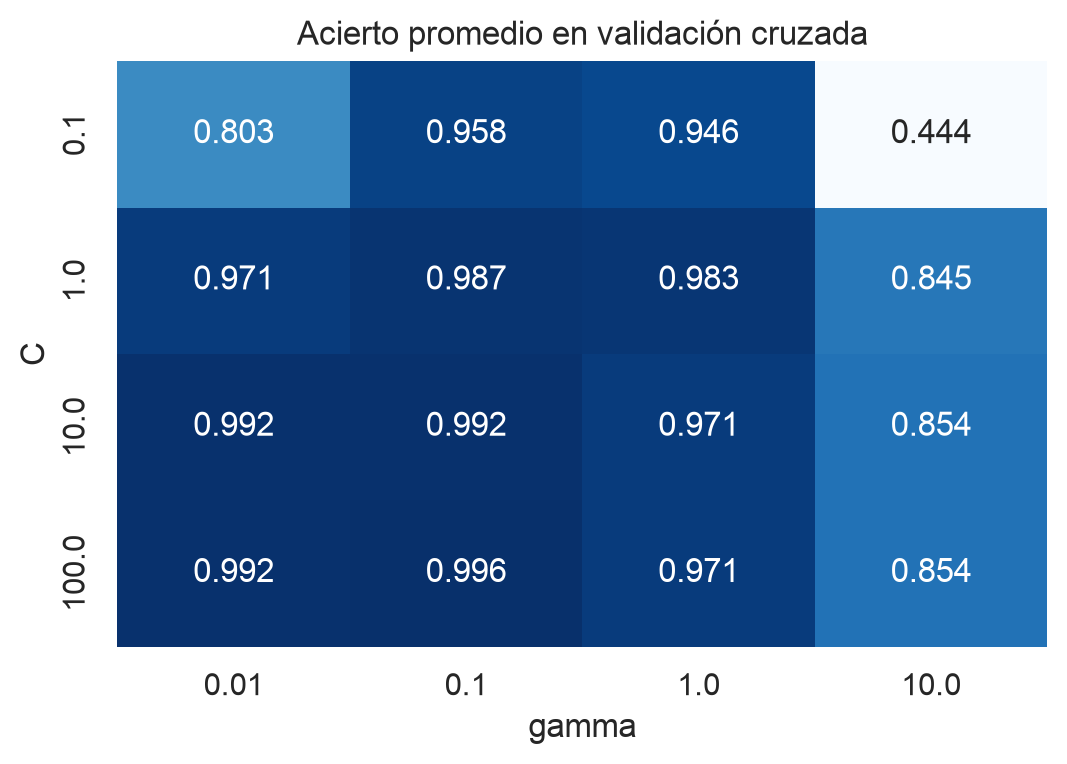

In [38]:
grilla = {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}
busqueda = GridSearchCV(SVC(kernel="rbf"), grilla, cv=5).fit(Z_tr, y_tr)

resultados = pd.DataFrame(busqueda.cv_results_)
tabla_cv = resultados.pivot(index="param_C", columns="param_gamma", values="mean_test_score").round(3)

plt.figure(figsize=(6, 3.8))
sns.heatmap(tabla_cv, annot=True, fmt=".3f", cmap="Blues", cbar=False)
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("Acierto promedio en validación cruzada")
plt.show()

In [39]:
print("mejores parámetros:", busqueda.best_params_)
print("acierto en validación cruzada:", round(busqueda.best_score_, 3))

# la prueba se usa una sola vez, al final, con el modelo elegido
prediccion_rbf = busqueda.predict(Z_te)
print("aciertos en prueba:", (prediccion_rbf == y_te).sum(), "de", len(y_te))

mejores parámetros: {'C': 100, 'gamma': 0.1}
acierto en validación cruzada: 0.996
aciertos en prueba: 101 de 103


## 6. SVR: predecir el salario de un jugador

**Objetivo:** usar SVM para predecir un número. Ahora la respuesta no es una especie, es el salario de un jugador.

**Los datos** son los de la clase 07: jugadores de béisbol de las grandes ligas, con sus estadísticas de la temporada 1986 y de toda su carrera, y su salario de 1987 en miles de dólares (James et al., 2013).

In [40]:
jugadores = pd.read_csv(BASE + "clase07/hitters_islr.csv")
print("filas y columnas:", jugadores.shape)
print("jugadores sin salario:", jugadores["Salary"].isna().sum())

filas y columnas: (322, 20)
jugadores sin salario: 59


In [41]:
jugadores.head()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.000,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.000,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.000,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.500,N


Cada fila es un jugador. `Salary` es el salario, lo que se quiere predecir. `AtBat`, `Hits`, `HmRun`, `Runs`, `RBI` y `Walks` son de la temporada 1986: turnos al bate, hits, jonrones, carreras anotadas, carreras impulsadas y bases por bolas. `Years` son las temporadas jugadas, y las columnas que empiezan con `C` son los mismos totales de toda la carrera. `PutOuts`, `Assists` y `Errors` son de la defensa. `League`, `Division` y `NewLeague` son texto.

Se quitan los jugadores sin salario, se renombran las columnas y las tres de texto pasan a ser variables 0 o 1, igual que en la clase 07.

In [42]:
jugadores = jugadores.dropna(subset=["Salary"])
nombres = {
    "AtBat": "turnos", "Hits": "hits", "HmRun": "jonrones", "Runs": "anotadas", "RBI": "impulsadas",
    "Walks": "bases_bolas", "Years": "temporadas", "CAtBat": "turnos_carrera", "CHits": "hits_carrera",
    "CHmRun": "jonrones_carrera", "CRuns": "anotadas_carrera", "CRBI": "impulsadas_carrera",
    "CWalks": "bases_bolas_carrera", "PutOuts": "outs_defensa", "Assists": "asistencias", "Errors": "errores",
}
X = jugadores.rename(columns=nombres)[list(nombres.values())].astype(float)
X["liga_nacional"] = (jugadores["League"] == "N").astype(float)
X["division_oeste"] = (jugadores["Division"] == "W").astype(float)
X["liga_nacional_1987"] = (jugadores["NewLeague"] == "N").astype(float)
y = jugadores["Salary"]

print("jugadores:", len(X), "| variables:", X.shape[1])
X.head()

jugadores: 263 | variables: 19


,turnos,hits,jonrones,anotadas,impulsadas,bases_bolas,temporadas,turnos_carrera,hits_carrera,jonrones_carrera,anotadas_carrera,impulsadas_carrera,bases_bolas_carrera,outs_defensa,asistencias,errores,liga_nacional,division_oeste,liga_nacional_1987
1,315.000,81.000,7.000,24.000,38.000,39.000,14.000,3449.000,835.000,69.000,321.000,414.000,375.000,632.000,43.000,10.000,1.000,1.000,1.000
2,479.000,130.000,18.000,66.000,72.000,76.000,3.000,1624.000,457.000,63.000,224.000,266.000,263.000,880.000,82.000,14.000,0.000,1.000,0.000
3,496.000,141.000,20.000,65.000,78.000,37.000,11.000,5628.000,1575.000,225.000,828.000,838.000,354.000,200.000,11.000,3.000,1.000,0.000,1.000
4,321.000,87.000,10.000,39.000,42.000,30.000,2.000,396.000,101.000,12.000,48.000,46.000,33.000,805.000,40.000,4.000,1.000,0.000,1.000
5,594.000,169.000,4.000,74.000,51.000,35.000,11.000,4408.000,1133.000,19.000,501.000,336.000,194.000,282.000,421.000,25.000,0.000,1.000,0.000


**Separar y estandarizar.** La mitad de los jugadores para entrenar y la otra mitad para probar, el mismo reparto de la clase 07. Las variables se estandarizan con la media y la desviación del entrenamiento.

In [43]:
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.5, random_state=1)
escala_b = StandardScaler().fit(X_ent)
Z_ent, Z_pru = escala_b.transform(X_ent), escala_b.transform(X_pru)
print("entrenamiento:", len(X_ent), "jugadores | prueba:", len(X_pru), "jugadores")

entrenamiento: 131 jugadores | prueba: 132 jugadores


## 7. SVR andando

**Entrenar y predecir.** Se entrena un `SVR` con sus valores por omisión (kernel radial, C = 1 y epsilon = 0,1) y se le pide el salario de cada jugador de prueba con `predict`. La tabla muestra los primeros 8 jugadores de prueba, con el salario real y el predicho.

In [44]:
svr = SVR().fit(Z_ent, y_ent)
prediccion = svr.predict(Z_pru)

comparacion = pd.DataFrame({"salario_real": y_pru, "salario_predicho": prediccion.round(0)})
comparacion.head(8)

,salario_real,salario_predicho
126,500.000,412.000
13,700.000,405.000
207,700.000,426.000
221,210.000,419.000
68,105.000,417.000
315,165.000,421.000
277,475.000,418.000
212,68.000,404.000


**¿Qué tan lejos queda?** El error se mide con el RMSE, como en la clase 07: es el error típico de la predicción, en miles de dólares. Se compara con el de predecir para todos el salario promedio del entrenamiento.

In [45]:
def rmse(real, predicho):
    return np.sqrt(np.mean((real - predicho) ** 2))

print(f"RMSE en prueba con SVR(): {rmse(y_pru, prediccion):.0f}")
print(f"RMSE en prueba si se predice siempre el promedio: {rmse(y_pru, y_ent.mean()):.0f}")
print(f"salario predicho más bajo y más alto: {prediccion.min():.0f} y {prediccion.max():.0f}")

RMSE en prueba con SVR(): 428
RMSE en prueba si se predice siempre el promedio: 416
salario predicho más bajo y más alto: 403 y 431


Con los valores por omisión, SVR no sirve: predice casi lo mismo para todos los jugadores, y le va peor que predecir el promedio. Los valores por omisión están pensados para una respuesta de tamaño cercano a 1, y aquí el salario está en miles de dólares. Hay que mover los parámetros.

## 8. Cómo cambia SVR con cada parámetro

**Objetivo:** ver qué hace cada parámetro de `SVR`.

Se cambia un parámetro a la vez. En cada tabla, una fila es un valor del parámetro, y las columnas son el RMSE en entrenamiento y en prueba. Mientras más chico el RMSE, mejor.

**El parámetro C** es el peso de los errores. Con C chico el modelo casi no los castiga.

In [46]:
filas = []
for C in [1, 10, 100, 1000, 10000, 100000]:
    modelo = SVR(C=C).fit(Z_ent, y_ent)
    filas.append({
        "C": C,
        "rmse_entrenamiento": round(rmse(y_ent, modelo.predict(Z_ent))),
        "rmse_prueba": round(rmse(y_pru, modelo.predict(Z_pru))),
    })
efecto_C = pd.DataFrame(filas)
efecto_C

,C,rmse_entrenamiento,rmse_prueba
0,1,491,428
1,10,454,390
2,100,345,296
3,1000,193,270
4,10000,6,278
5,100000,0,278


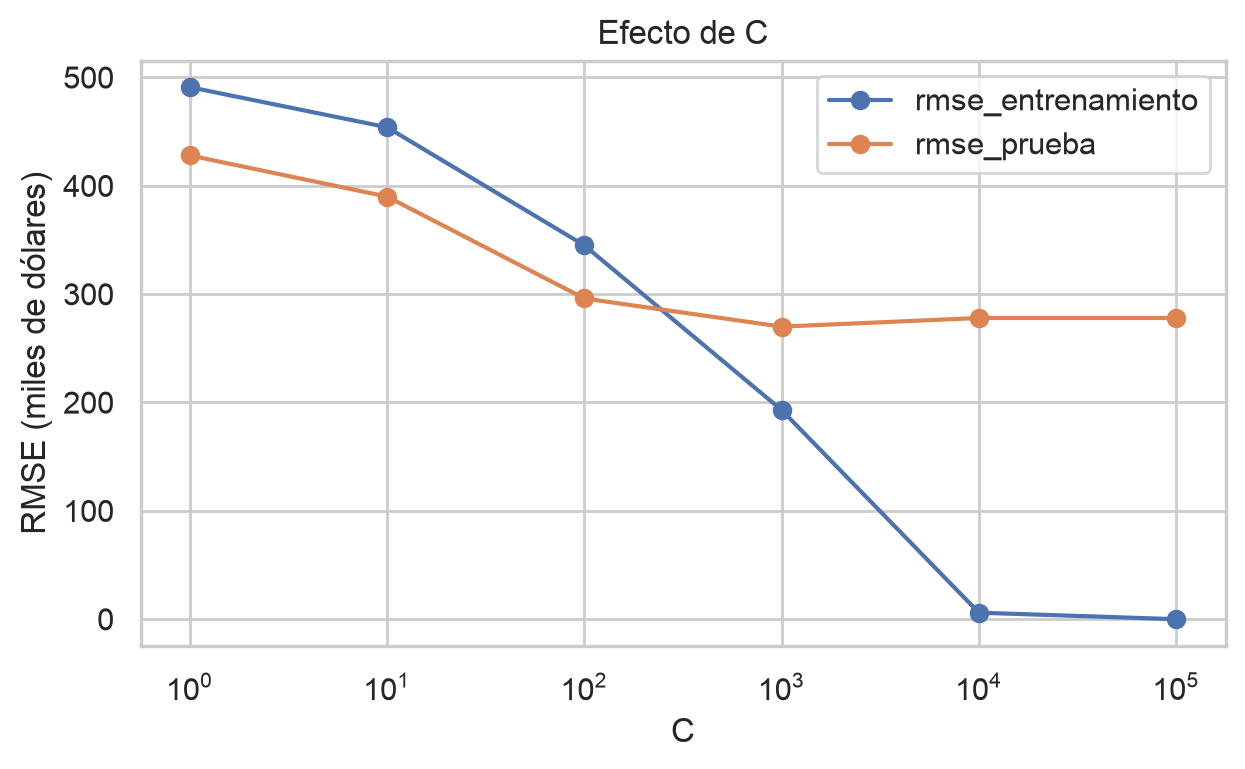

In [47]:
efecto_C.plot(x="C", y=["rmse_entrenamiento", "rmse_prueba"], marker="o", logx=True, figsize=(7, 3.8))
plt.ylabel("RMSE (miles de dólares)")
plt.title("Efecto de C")
plt.show()

Con C = 1.000 el RMSE de prueba baja de 428 a 270. Con C más grande el error de entrenamiento llega a 0, porque el modelo se aprende los salarios de memoria, y el de prueba no mejora.

**El parámetro epsilon** es el medio ancho del tubo, en miles de dólares: los errores menores que epsilon no cuentan. Se usa C = 1.000. La tabla agrega cuántos vectores de soporte quedan.

In [48]:
filas = []
for epsilon in [0.1, 10, 50, 100, 200, 500]:
    modelo = SVR(C=1000, epsilon=epsilon).fit(Z_ent, y_ent)
    filas.append({
        "epsilon": epsilon,
        "vectores_soporte": len(modelo.support_),
        "rmse_entrenamiento": round(rmse(y_ent, modelo.predict(Z_ent))),
        "rmse_prueba": round(rmse(y_pru, modelo.predict(Z_pru))),
    })
pd.DataFrame(filas)

,epsilon,vectores_soporte,rmse_entrenamiento,rmse_prueba
0,0.100,131,193,270
1,10.000,123,192,269
2,50.000,95,190,268
3,100.000,69,191,268
4,200.000,52,212,284
5,500.000,28,358,381


Hasta epsilon = 100 el error casi no cambia, y los vectores de soporte bajan de 131 a 69. Con epsilon = 500 casi todos los jugadores caben en el tubo y el error sube.

**El parámetro gamma**, con C = 1.000 y epsilon = 10. Como con los pingüinos, dice qué tan rápido baja el parecido entre dos jugadores con la distancia.

In [49]:
filas = []
for gamma in [0.001, 0.01, 0.1, 1, 10]:
    modelo = SVR(C=1000, epsilon=10, gamma=gamma).fit(Z_ent, y_ent)
    filas.append({
        "gamma": gamma,
        "rmse_entrenamiento": round(rmse(y_ent, modelo.predict(Z_ent))),
        "rmse_prueba": round(rmse(y_pru, modelo.predict(Z_pru))),
    })
efecto_gamma = pd.DataFrame(filas)
efecto_gamma

,gamma,rmse_entrenamiento,rmse_prueba
0,0.001,360,316
1,0.010,291,273
2,0.100,135,272
3,1.000,138,398
4,10.000,141,417


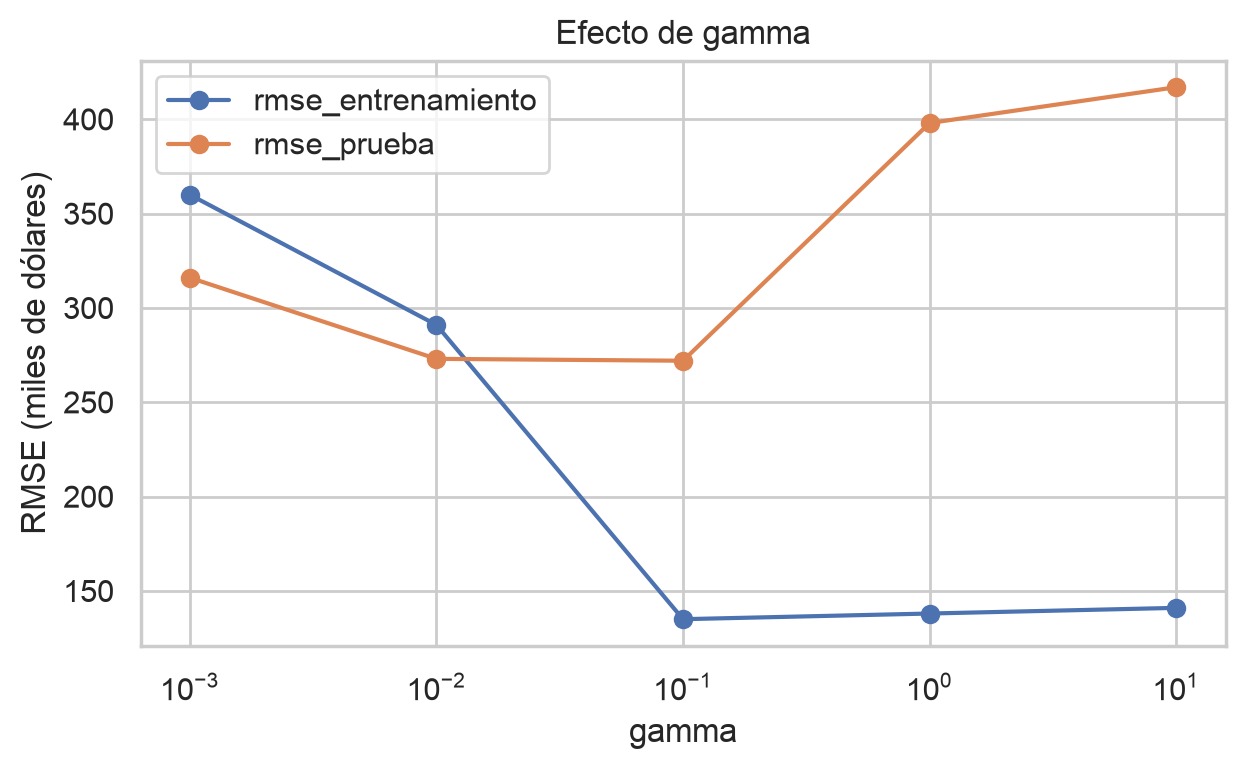

In [50]:
efecto_gamma.plot(x="gamma", y=["rmse_entrenamiento", "rmse_prueba"], marker="o", logx=True, figsize=(7, 3.8))
plt.ylabel("RMSE (miles de dólares)")
plt.title("Efecto de gamma")
plt.show()

Con gamma = 1 o más, el error de entrenamiento es bajo y el de prueba sube a cerca de 400. Es sobreajuste, igual que con los pingüinos.

**Elegir los tres a la vez, con validación cruzada.** `GridSearchCV` prueba todas las combinaciones de C, epsilon y gamma dentro del entrenamiento. Ahora mide el RMSE (`scoring="neg_root_mean_squared_error"`; scikit-learn lo entrega con signo negativo para que siempre gane el mayor).

In [51]:
grilla = {"C": [10, 30, 100, 300, 1000, 3000], "epsilon": [10, 50, 100], "gamma": [0.005, 0.01, 0.02, 0.05, 0.1]}
busqueda_svr = GridSearchCV(SVR(kernel="rbf"), grilla, cv=5, scoring="neg_root_mean_squared_error").fit(Z_ent, y_ent)

print("mejores parámetros:", busqueda_svr.best_params_)
print(f"RMSE en prueba: {rmse(y_pru, busqueda_svr.predict(Z_pru)):.0f}")

mejores parámetros: {'C': 3000, 'epsilon': 10, 'gamma': 0.005}
RMSE en prueba: 277


**Comparación con los modelos de la clase 07**, con los mismos datos de prueba.

In [52]:
modelos = {
    "mínimos cuadrados": LinearRegression().fit(Z_ent, y_ent),
    "Ridge": RidgeCV(alphas=np.logspace(-2, 5, 200), cv=5).fit(Z_ent, y_ent),
    "Lasso": LassoCV(cv=5, random_state=0, max_iter=100000).fit(Z_ent, y_ent),
    "SVR": busqueda_svr,
}
filas = []
for nombre, modelo in modelos.items():
    filas.append({"modelo": nombre, "rmse_prueba": round(rmse(y_pru, modelo.predict(Z_pru)))})
pd.DataFrame(filas)

,modelo,rmse_prueba
0,mínimos cuadrados,342
1,Ridge,316
2,Lasso,325
3,SVR,277


El salario predicho contra el real, para Ridge y para SVR. Si la predicción fuera perfecta, los puntos caerían sobre la diagonal.

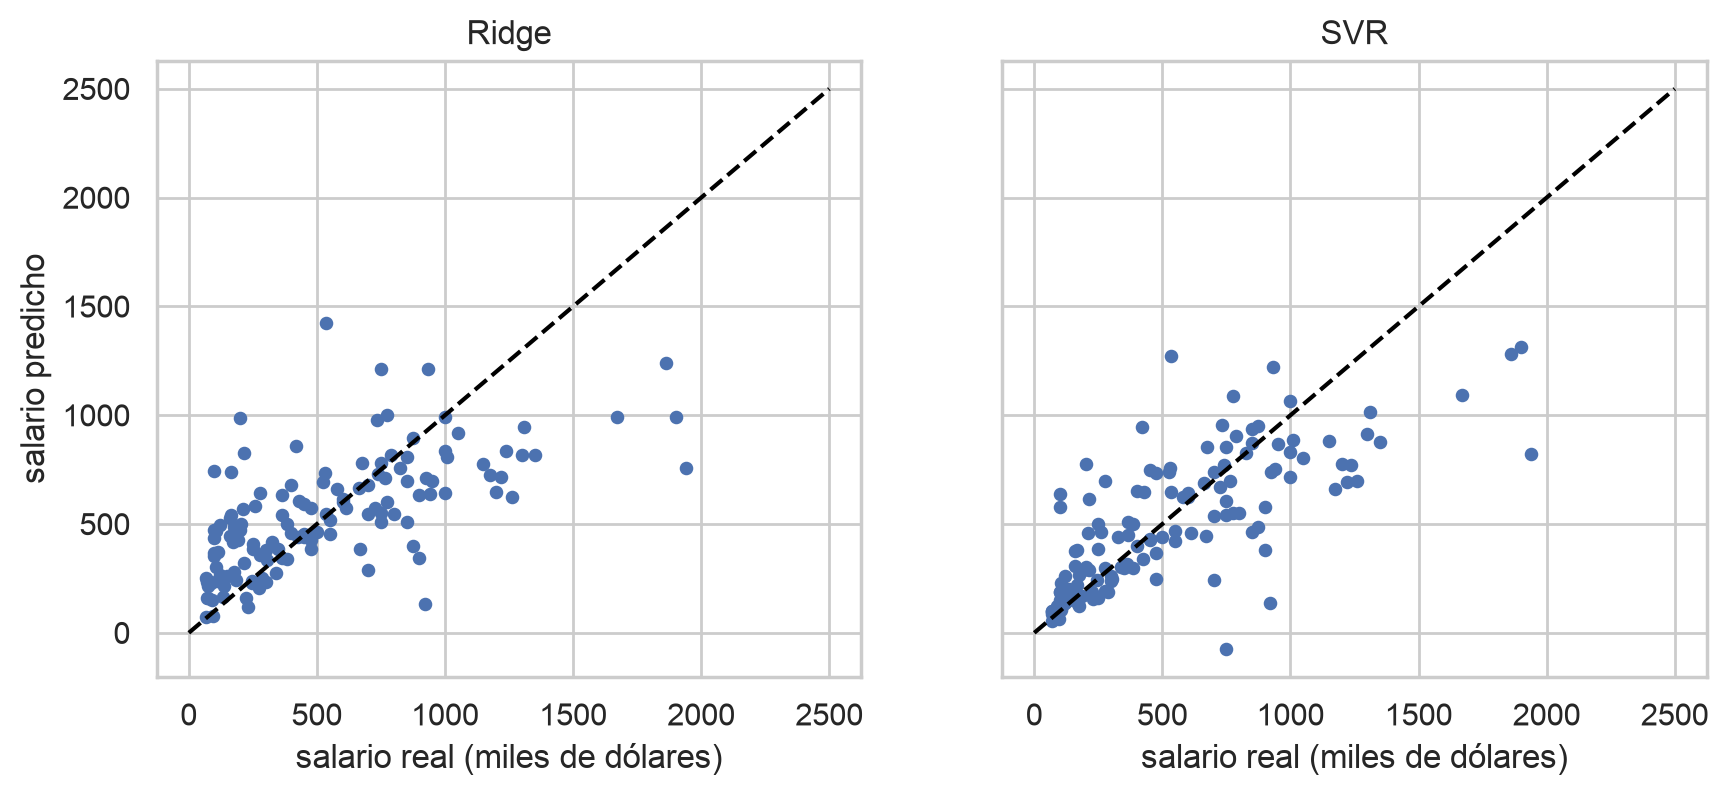

In [53]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for eje, nombre in zip(ejes, ["Ridge", "SVR"]):
    eje.scatter(y_pru, modelos[nombre].predict(Z_pru), s=15)
    eje.plot([0, 2500], [0, 2500], color="black", linestyle="--")
    eje.set_title(nombre)
    eje.set_xlabel("salario real (miles de dólares)")
ejes[0].set_ylabel("salario predicho")
plt.show()

---

**Próximas fechas.** La Tarea 2 se entrega el lunes 16 de noviembre por Aula. El viernes 20 de noviembre es el Control Q4, al inicio de la clase. El viernes 27 de noviembre es el Certamen 2, con las unidades 6 a 9.